This notebook reproduces Fig. 19. We study how the reconstruction error of the pulses (see `Fig06cd-three_level_system.ipynb` and `Fig18-error_shuttling_model.ipynb`),
$$
\mathcal{E} = \int_0^1d\tau|\varepsilon(\tau)-\varepsilon'(\tau)|,
$$
translates into the transfer fidelity. To this end, we drive the system with the exact pulse $\varepsilon(\tau)$ and with its reconstruction $\varepsilon'(\tau)$ for the same total time $t_\mathrm{f}$, and compute the fidelities $\mathcal{F}[\varepsilon]$ and $\mathcal{F}[\varepsilon']$ from the coherent time evolution. In both cases, the initial and target states are the first excited eigenstates of the Hamiltonian at the initial and final values of the pulse.

We consider two sets of pulses:
- (a) The $\Lambda$-system with $(\alpha,\beta)=(2,2)$ for $\tau_{1,2}/\tau_0\in[0.1,10]$, reconstructed with the (symmetric) LZ basis, and $t_\mathrm{f}=10/\tau_0$.
- (b) The shuttling Hamiltonian with the parameters of Fig. 11 for $(\alpha,\beta)\in[-3,3]^2$, reconstructed with the split basis, and $t_\mathrm{f}=100/t_c$.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import qutip as qt
from matplotlib.colors import ListedColormap

from HQUAD_lib.parallel_utils import parameter_run
from HQUAD_lib.QUAD_utils import solve_LZ
from HQUAD_lib.hamiltonians import lambda_system, two_valleys_system
from HQUAD_lib.utils import independent_basis, split_basis, compute_pulse_and_approx

In [2]:
def compute_fidelity(eps_sol: np.ndarray, tf: float, H_0: np.ndarray, H_driving: np.ndarray,
                     adiabatic_state: int = 1) -> float:
    """
    Fidelity of the transfer between the instantaneous eigenstates (with index adiabatic_state) of the Hamiltonian
    H(t) = H_0 + eps(t) H_driving at the initial and final times, for the coherent evolution.
    """
    time = np.linspace(0, tf, len(eps_sol))

    H_T = qt.QobjEvo([qt.Qobj(H_0), [qt.Qobj(H_driving), qt.coefficient(eps_sol, tlist=time)]])

    psi_0 = qt.Qobj(H_T(0)).eigenstates()[1][adiabatic_state]
    psi_target = qt.Qobj(H_T(tf)).eigenstates()[1][adiabatic_state]

    options = {'store_states': False, 'store_final_state': True, 'atol': 1e-10, 'rtol': 1e-8, 'nsteps': 10 ** 7}
    psi_f = qt.sesolve(H_T, psi_0, [0, tf], options=options).final_state

    return qt.fidelity(psi_target, psi_f) ** 2

# LZ basis

In [3]:
alphas_basis = np.linspace(-25, 60, 201)  # Increase to obtain lower errors
alphas_basis[0] = -np.inf
alphas_basis[-1] = np.inf

zs_sol = parameter_run(solve_LZ, 'alpha', alphas_basis, beta=0, reduction=3)
s = np.linspace(0, 1, len(zs_sol[0]))
ds = np.abs(s[1] - s[0])

independent_functions, G_independent = independent_basis(zs_sol, ds)
split_functions, G_split = split_basis(independent_functions, ds)

print(f'Number of elements in the basis: {len(independent_functions)}')
print(f'Number of elements in the split basis: {len(split_functions)}')

solve_LZ: [['alpha']]:   0%|          | 0/201 [00:00<?, ?it/s]

Number of elements in the basis: 34
Number of elements in the split basis: 53


# (a) $\Lambda$-system

In [4]:
eps12 = 0
eps23_s = np.linspace(-40, 40, 2 ** 15 + 1)
partial_hamiltonian_3ls = np.array([lambda_system(0, 1, 0, 0) for _ in range(len(eps23_s))])

alpha = 2
beta = 2
adiabatic_state = 1

n_taus = 15  # Increase to enhance the resolution (50 values in the manuscript)
taus_1 = np.linspace(0.1, 10, n_taus)
taus_2 = np.linspace(0.1, 10, n_taus)

tf_3ls = 10


def compute_pulses_3ls(tau1: float, tau2: float):
    hypermatrix = np.array([lambda_system(eps12, eps23, tau1, tau2) for eps23 in eps23_s])
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    return compute_pulse_and_approx(eigvalues, eigmodes, eps23_s, partial_hamiltonian_3ls, alpha, beta, adiabatic_state,
                                    independent_functions, G_independent, limit_sup=np.inf, limit_inf=0)


def compute_fidelities_3ls(tau1: float, tau2: float, eps_sol: np.ndarray, eps_approx: np.ndarray):
    H_0 = lambda_system(eps12, 0, tau1, tau2)
    H_driving = lambda_system(0, 1, 0, 0)

    F_original = compute_fidelity(eps_sol, tf_3ls, H_0, H_driving, adiabatic_state=adiabatic_state)
    F_approx = compute_fidelity(eps_approx, tf_3ls, H_0, H_driving, adiabatic_state=adiabatic_state)
    return F_original, F_approx

In [5]:
pulses_3ls = parameter_run(compute_pulses_3ls, [['tau1'], ['tau2']], [[taus_1], [taus_2]], reshape=False)
eps_sols_3ls = np.array(pulses_3ls[0])
eps_approxs_3ls = np.array(pulses_3ls[1])

errors_3ls = np.sum(np.abs(eps_sols_3ls - eps_approxs_3ls), axis=1) * ds

taus = np.array([[tau1, tau2] for tau1 in taus_1 for tau2 in taus_2])
fidelities_original_3ls, fidelities_approx_3ls = parameter_run(
    compute_fidelities_3ls, [['tau1', 'tau2', 'eps_sol', 'eps_approx']],
    [[taus[:, 0], taus[:, 1], eps_sols_3ls, eps_approxs_3ls]])

compute_pulses_3ls: [['tau1'], ['tau2']]:   0%|          | 0/225 [00:00<?, ?it/s]

compute_fidelities_3ls: [['tau1', 'tau2'(...)]:   0%|          | 0/225 [00:00<?, ?it/s]

# (b) Shuttling model

In [6]:
tc = 1
phiL = 0
phiR = 0.8 * np.pi
DeltaL = 1
DeltaR = 2

eps_s = np.linspace(-10, 10, 2 ** 18 + 1)  # 2 ** 20 + 1 points in the manuscript
partial_hamiltonian_4ls = np.array([two_valleys_system(1, 0, 0, 0, 0, 0) for _ in range(len(eps_s))])

hypermatrix = np.array([two_valleys_system(eps, tc, phiL, phiR, DeltaL, DeltaR) for eps in eps_s])
eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

n_values = 13  # Increase to enhance the resolution (51 values in the manuscript)
alphas = np.linspace(-3, 3, n_values)
betas = np.linspace(-3, 3, n_values)

tf_4ls = 100

pulses_4ls = parameter_run(compute_pulse_and_approx, [['alpha'], ['beta']], [[alphas], [betas]], reshape=False,
                           eigvalues=eigvalues, eigmodes=eigmodes, driving_parameter=eps_s,
                           partial_hamiltonian=partial_hamiltonian_4ls, adiabatic_state=1,
                           independent_functions=split_functions, G_independent=G_split, limit_sup=1e10, limit_inf=0)
eps_sols_4ls = np.array(pulses_4ls[0])
eps_approxs_4ls = np.array(pulses_4ls[1])

errors_4ls = np.sum(np.abs(eps_sols_4ls - eps_approxs_4ls), axis=1) * ds

compute_pulse_and_approx: [['alpha'], ['(...)]:   0%|          | 0/169 [00:00<?, ?it/s]

In [7]:
H_0 = two_valleys_system(0, tc, phiL, phiR, DeltaL, DeltaR)
H_driving = two_valleys_system(1, 0, 0, 0, 0, 0)

fidelities_original_4ls = parameter_run(compute_fidelity, 'eps_sol', eps_sols_4ls, tf=tf_4ls, H_0=H_0,
                                        H_driving=H_driving)
fidelities_approx_4ls = parameter_run(compute_fidelity, 'eps_sol', eps_approxs_4ls, tf=tf_4ls, H_0=H_0,
                                      H_driving=H_driving)

compute_fidelity: [['eps_sol']]:   0%|          | 0/169 [00:00<?, ?it/s]

compute_fidelity: [['eps_sol']]:   0%|          | 0/169 [00:00<?, ?it/s]

# Plot

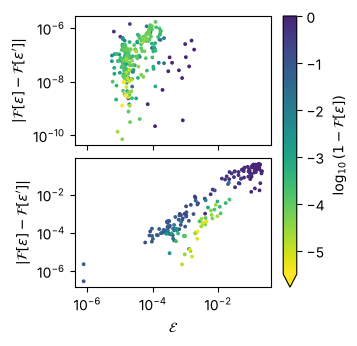

In [8]:
cmap = ListedColormap(mpl.colormaps['viridis_r'](np.linspace(0, 0.9, 256)))

infid_3ls = np.log10(1 - fidelities_original_3ls)
infid_4ls = np.log10(1 - fidelities_original_4ls)

# Plot the high-fidelity points on top
idx_3ls = np.argsort(infid_3ls)[::-1]
idx_4ls = np.argsort(infid_4ls)[::-1]

fig, axs = plt.subplots(2, 1, figsize=(3.4, 3.5), sharex=True)

im = axs[0].scatter(errors_3ls[idx_3ls], np.abs(fidelities_original_3ls - fidelities_approx_3ls)[idx_3ls], s=3,
                    c=infid_3ls[idx_3ls], cmap=cmap, vmin=-5.5, vmax=0)

axs[1].scatter(errors_4ls[idx_4ls], np.abs(fidelities_original_4ls - fidelities_approx_4ls)[idx_4ls], s=3,
               c=infid_4ls[idx_4ls], cmap=cmap, vmin=-5.5, vmax=0)

for ax in axs:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylabel(r"$|\mathcal{F}[\varepsilon] - \mathcal{F}[\varepsilon']|$")

axs[-1].set_xlabel(r'$\mathcal{E}$')

fig.tight_layout()
fig.subplots_adjust(hspace=0.1)
plt.colorbar(im, ax=axs, label=r'$\log_{10}(1 - \mathcal{F}[\varepsilon])$', extend='min');